In [ ]:
#Assignment 2: Testing data analysis skills with pandas, numpy, and matplotlib. Use the dataset from the zip file.
#Total points: 24

#You are allowed to seek help from your classmates; however, it should be your own work.
#You can not copy or paste their work. If you seek help, you need to acknowledge it in your submission.
#You will submit the commented and outputs-printed Jupyter Notebook file

#Remove all unnecessary code and outputs. 


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix #You may or may not need


In [2]:
df = pd.read_csv("used_device_data.csv")

In [6]:
#Question 1: Report any data limitations. Your response must be generated using Python

#code; do not calculate or analyze this manually. (1 point)


print("Dataset shape", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

missing = df.isnull().sum()
missing = missing[missing > 0]

print("\nData limitations:")
print(missing)
print("There are", df.duplicated().sum(), "duplicated rows.")
      

Dataset shape (3454, 15)

Missing values:
device_brand               0
os                         0
screen_size                0
4g                         0
5g                         0
rear_camera_mp           179
front_camera_mp            2
internal_memory            4
ram                        4
battery                    6
weight                     7
release_year               0
days_used                  0
normalized_used_price      0
normalized_new_price       0
dtype: int64

Duplicate rows: 0

Data types:
device_brand              object
os                        object
screen_size              float64
4g                        object
5g                        object
rear_camera_mp           float64
front_camera_mp          float64
internal_memory          float64
ram                      float64
battery                  float64
weight                   float64
release_year               int64
days_used                  int64
normalized_used_price    float64
normalized_new_p

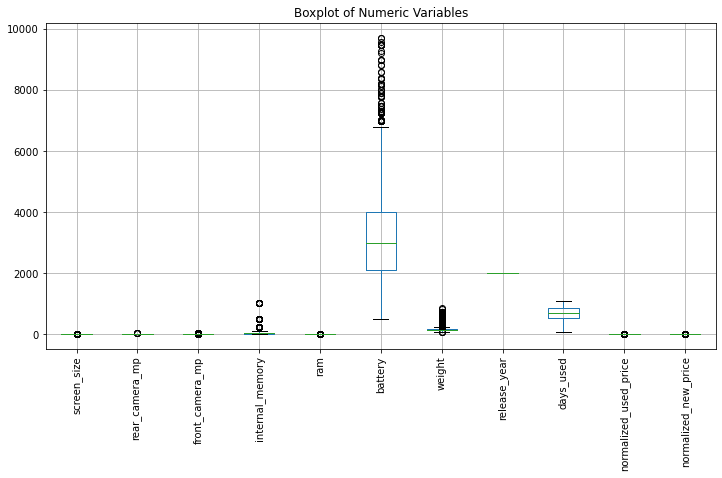

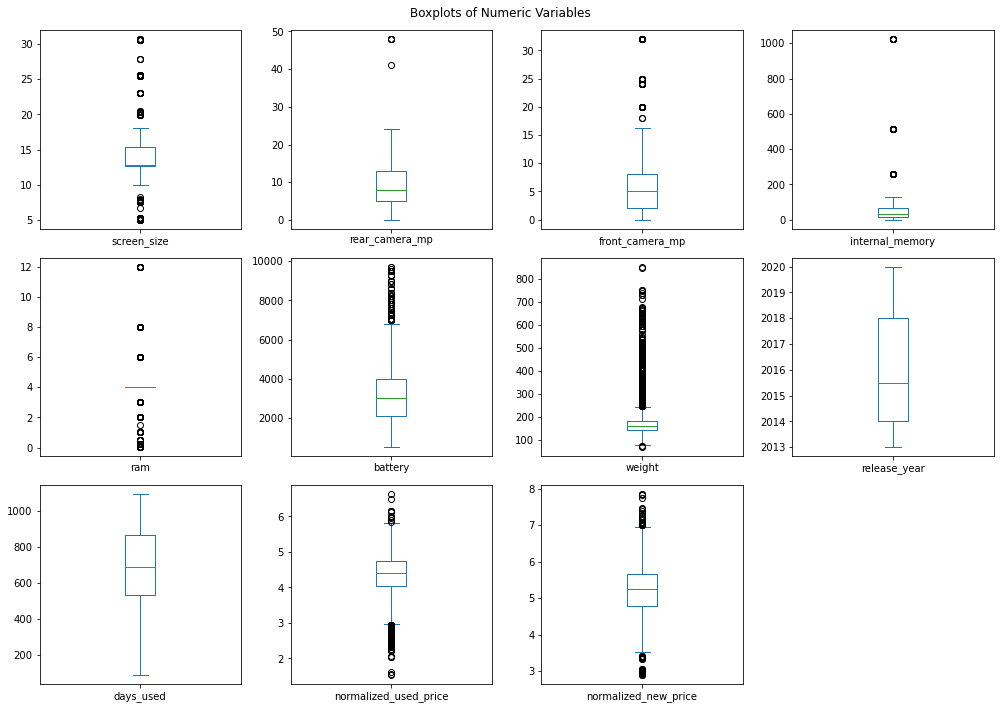

The boxplots show potential outliers in several variables, particularly internal_memory, battery, weight, normalized_used_price, and normalized_new_price.  Weight and battery show many high-value outliers, while the normalized price variables contain outliers on both the low and high ends.


In [10]:
#Question 2: Comment on outliers using visualization. (2 points)
df.boxplot(figsize=(12,6))
plt.xticks(rotation=90)
plt.title("Boxplot of Numeric Variables")
plt.show()

numeric_cols = df.select_dtypes(include=np.number).columns

df[numeric_cols].plot(
    kind="box",
    subplots=True,
    layout=(3,4),
    figsize=(14, 10)
)

plt.suptitle("Boxplots of Numeric Variables")
plt.tight_layout()
plt.show()

print("The boxplots show potential outliers in several variables, particularly internal_memory, battery, weight, normalized_used_price, and normalized_new_price.  Weight and battery show many high-value outliers, while the normalized price variables contain outliers on both the low and high ends.")

In [12]:
#Question 3: Create a new column device_age that represents the age of the device in years. Print the mean device age. (1 point)
df["device_age"] = 2020 - df["release_year"]

print("Mean device age:", df["device_age"].mean())

Mean device age: 4.034742327735958


In [13]:
#Question 4: Now, start using numpy functions to generate insights from the data
#Question 4a: Calculate the average, minimum, and maximum values of days_used using numpy and print them.  (1 point)
print("Average days used:", np.mean(df["days_used"]))
print("Minimum days used:", np.min(df["days_used"]))
print("Maximum days used:", np.max(df["days_used"]))

Average days used: 674.8697162709901
Minimum days used: 91
Maximum days used: 1094


In [15]:
#Question 4b: Calculate and print standard deviation and variance of normalized_used_price. (1 point)
print("Standard deviation:", np.std(df["normalized_used_price"]))
print("Variance:", np.var(df["normalized_used_price"]))

Standard deviation: 0.5888283607206612
Variance: 0.3467188383889811


In [17]:
#Question 4c: Calculate the 25th, 50th, and 75th percentiles of normalized_new_price and normalized_used_price. (1 point)

print("New price percentiles:", 
      np.percentile(df["normalized_new_price"], [25, 50, 75]))

print("Used price percentiles:",
      np.percentile(df["normalized_used_price"], [25, 50, 75]))

New price percentiles: [4.79034184 5.24589185 5.67371825]
Used price percentiles: [4.03393085 4.40513262 4.75570001]


In [18]:
#Question 4d: Count the number of devices in the data that have a normalized used price of less than 4.5. (1 point)
count = np.sum(df["normalized_used_price"] < 4.5)
print("Number of devices with normalized used price less than 4.5:", count)

Number of devices with normalized used price less than 4.5: 2001


In [19]:
#Question 5: We often deal with massive datasets. In such cases, sampling is a useful approach. 
#Randomly sample 500 devices from the dataset and calculate the average normalized_used_price and print. (1 point)
sample = df.sample(n=500, random_state=1)

average_price = sample["normalized_used_price"].mean()

print("Average normalized used price of sample", average_price)

Average normalized used price of sample 4.356125452824001


In [22]:
#Question 7a: Calculate the z-scores of normalized_used_price to identify outliers. 
#You can use 3 standard deviations to identify outliers. 
#Print the number of outliers. (2 points)
mean_price = np.mean(df["normalized_used_price"])
std_price = np.std(df["normalized_used_price"])

z_scores = (df["normalized_used_price"] - mean_price) / std_price

outliers = df[np.abs(z_scores) > 3]

print("Number of outliers:", len(outliers))

Number of outliers: 35


In [24]:
# Question 7b: Continuing from 7a, you are now interested to know why these are outliers. 
    #You think that days_used, internal_memory, and weight could be the reasons. 
#Compare these three variables of your outliers and the whole data and print them. Comment on your results.
#Hint: Create a separate dataframe (subset) for the outliers. (3 points)

variables = ["days_used", "internal_memory", "weight"]

print("Outlier averages:")
print(outliers[variables].mean())

print("\nWhole dataset averages:")
print(df[variables].mean())


Outlier averages:
days_used          679.971429
internal_memory    177.489697
weight             140.662857
dtype: float64

Whole dataset averages:
days_used          674.869716
internal_memory     54.573099
weight             182.751871
dtype: float64


The outliers have much higher internal memory and lower weight than the whole dataset, while days used is very similar.  Internal memory and weight may help explain the unusual used prices.


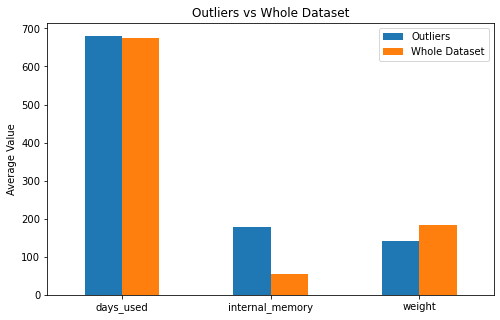

In [28]:
#Question 7c: Plot these comparisons. You can choose the chart that you think will be more appropriate for visualization. (3 points)

print("The outliers have much higher internal memory and lower weight than the whole dataset, while days used is very similar.  Internal memory and weight may help explain the unusual used prices.")

comparison = pd.DataFrame({
    "Outliers": outliers[variables].mean(),
    "Whole Dataset":  df[variables].mean()
})

comparison.plot(kind="bar", figsize=(8,5))
plt.title("Outliers vs Whole Dataset")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.show()

In [ ]:
#Continue Case 2 with stattsmodels

In [33]:
#Question 8: Create a multiple linear regression model using the following independent variables
#internal_memory, battery, weight, days_used, 5g_yes
#Your dependent variable is normalized_used_price
#Explain the coefficients properly (4 points)

import statsmodels.api as sm

df["5g_yes"] = (df["5g"] == "yes").astype(int)

X = df[["internal_memory", "battery", "weight", "days_used", "5g_yes"]]
y = df["normalized_used_price"]

X = sm.add_constant(X)

model = sm.OLS(y, X, missing="drop").fit()

print(model.summary())

print(df["5g"].value_counts())

# Interpretation:
# Internal memory and battery have positive relationships with normalized used price.
# Days used has a negative relationship, meaning older/more-used phones tend to have lower prices.
# 5G phones have a normalized used price about 0.441 higher than non-5G phones,
# holding the other variables constant.
# Weight has a small negative coefficient but is not statistically significant at the 5% level.



                              OLS Regression Results                             
Dep. Variable:     normalized_used_price   R-squared:                       0.424
Model:                               OLS   Adj. R-squared:                  0.424
Method:                    Least Squares   F-statistic:                     506.0
Date:                   Mon, 28 Sep 2026   Prob (F-statistic):               0.00
Time:                           17:00:31   Log-Likelihood:                -2089.1
No. Observations:                   3437   AIC:                             4190.
Df Residuals:                       3431   BIC:                             4227.
Df Model:                              5                                         
Covariance Type:               nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const       

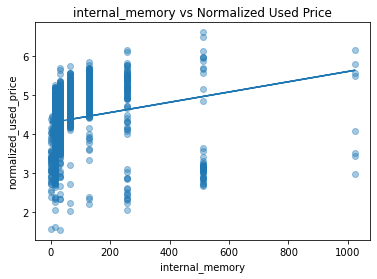

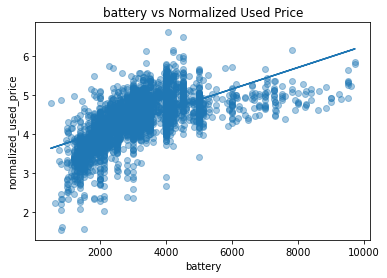

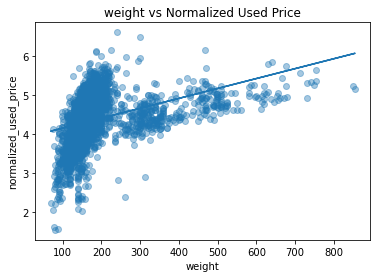

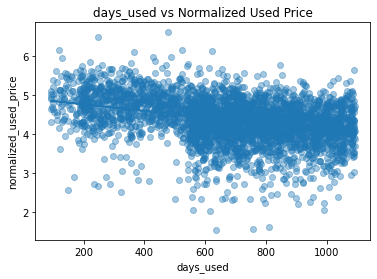

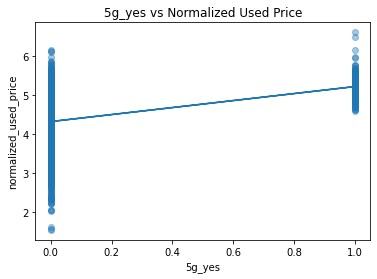

In [38]:
#Question 9:Develop scatterplots of each independent variable with the dependent variable with the regression lines.
# List of predictor variables (2 points)

import matplotlib.pyplot as plt
import numpy as np

predictors = ["internal_memory", "battery", "weight", "days_used", "5g_yes"]

for variable in predictors:

    temp = df[[variable, "normalized_used_price"]].dropna()

    x = temp[variable]
    y = temp["normalized_used_price"]
        
    plt.figure(figsize=(6,4))
    plt.scatter(x, y, alpha=0.4)

    m, b = np.polyfit(x, y, 1)
    plt.plot(x, m*x + b)

    plt.xlabel(variable)
    plt.ylabel("normalized_used_price")
    plt.title(variable + " vs Normalized Used Price")

    plt.show()

    # The scatterplots show that days_used has a negative relationship
    # with normalized used price, while 5G has a positive relationship.
    # Internal memory and battery also show positive relationships.
    # Weight appears to have a relatively weak relationship with used price.